In [1]:
#!/usr/bin/env python3
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass


### Get B2TF recast data

In [2]:
b2tf_DF = pd.read_csv('../b2tf_effs_13TeV_y21_3.csv')
b2tf_DF['dm'] = (b2tf_DF['m1']-b2tf_DF['m0']).round(0)
b2tf_DF['ctau'] = (b2tf_DF['tau']*2.99e8).round(0)
b2tf_DF['ctau_full'] = (b2tf_DF['tau']*2.99e8)
b2tf_DF['xsec_fb'] = (b2tf_DF['xsec_pb']*1e3)
b2tf_DF['N_Run2'] = b2tf_DF['eff']*b2tf_DF['xsec_fb']*139.0
b2tf_DF['N_Run2_err'] = b2tf_DF['efferror']*b2tf_DF['xsec_fb']*139.0
# Remove large deltaM, which results in promptly decaying chi1 through the process chi1 -> chi2* + h -> (chi0 + h) + h
b2tf_DF = b2tf_DF[b2tf_DF['dm'] < 250.0].copy()



In [3]:
b2tf_DF['ms'].unique(),b2tf_DF['ctau'].unique()

(array([ 300.,  700.,  900., 1100.,  500.]), array([10., 20., 49., 50.]))

## Plot Effs

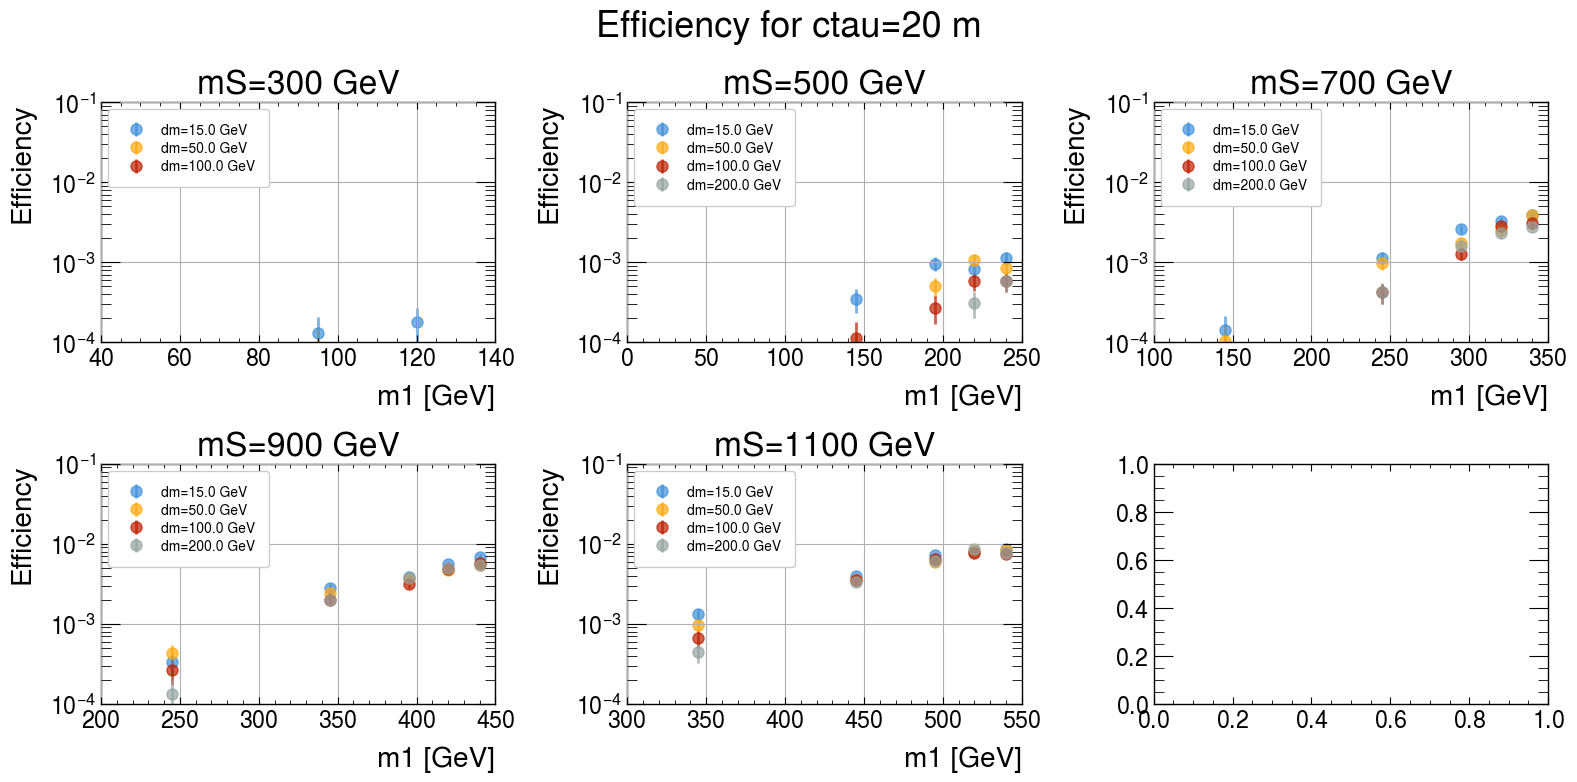

In [4]:
mSValues = sorted(b2tf_DF['ms'].unique())
ncolumns = 3
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = b2tf_DF['ctau'].unique()
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
ctau = 20.0
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['ctau'].round(0) == ctau)].sort_values(by=['dm', 'm1'])
    alpha=0.7
    for dm,dfB in df.groupby('dm'):        
        axes[iax].errorbar(dfB['m1'], dfB['eff'], 
                           yerr=dfB['efferror'], fmt='o', label=f'dm={dm:.1f} GeV', alpha=alpha)
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel('Efficiency')
    axes[iax].legend(fontsize=10,frameon=True,framealpha=1,facecolor='white',loc='upper left')
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-4, 1e-1)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'Efficiency for ctau={ctau:.0f} m', fontsize=26)
plt.tight_layout()
plt.show()

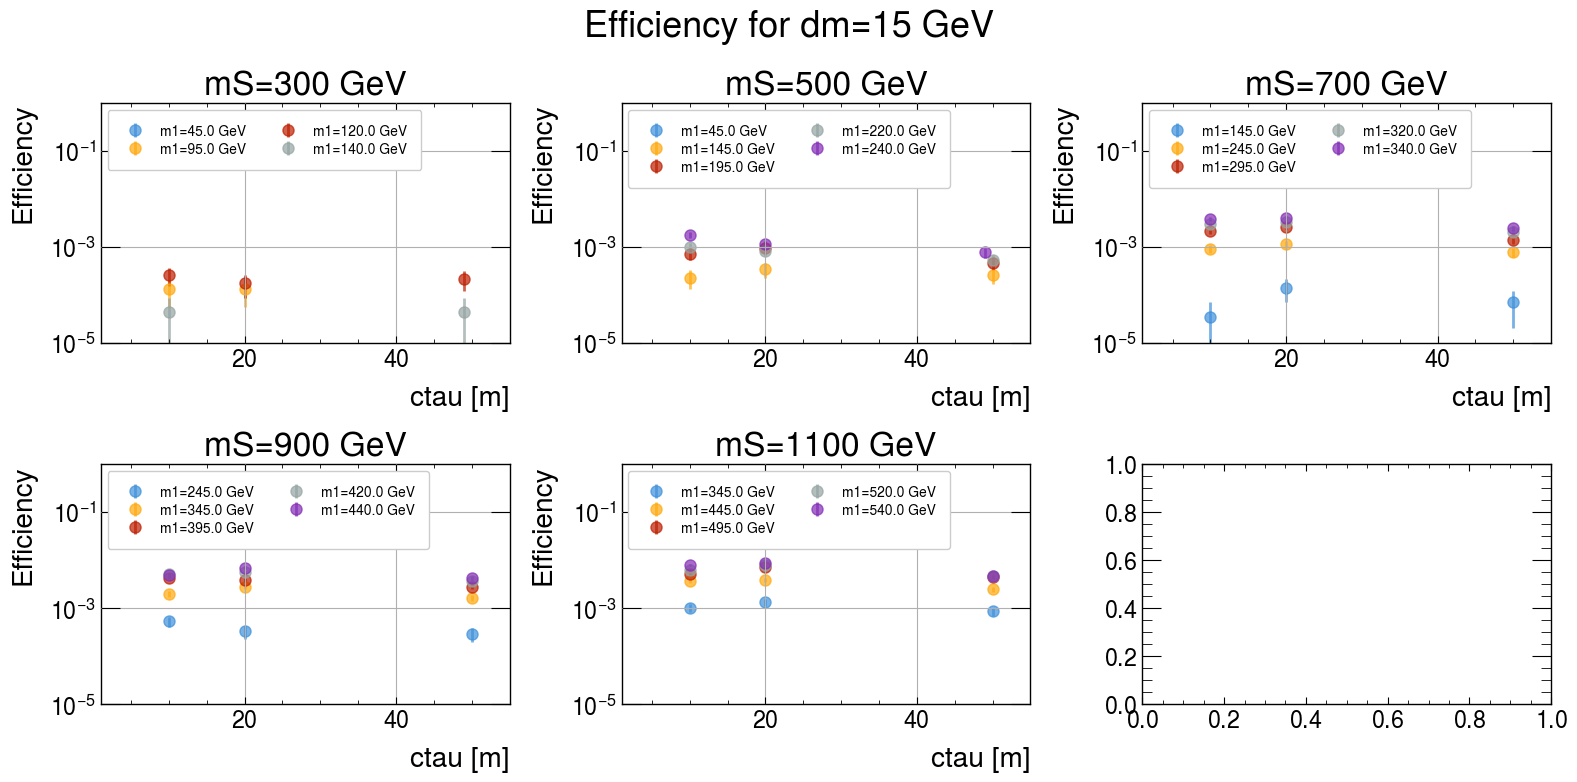

In [5]:
mSValues = sorted(b2tf_DF['ms'].unique())
ncolumns = 3
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = b2tf_DF['ctau'].unique()
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
dm = 15.0
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['dm'].round(0) == dm)].sort_values(by=['m1', 'ctau'])
    alpha=0.7
    for m1,dfB in df.groupby('m1'):        
        axes[iax].errorbar(dfB['ctau'], dfB['eff'], 
                           yerr=dfB['efferror'], fmt='o', label=f'm1={m1:.1f} GeV', alpha=alpha)
        
    axes[iax].set_xlabel('ctau [m]')
    axes[iax].set_ylabel('Efficiency')
    axes[iax].legend(fontsize=10,loc='upper left',ncol=2,frameon=True,framealpha=1,facecolor='white')
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-5, 1)
    axes[iax].set_xlim(1,55)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'Efficiency for dm={dm:.0f} GeV', fontsize=26)
plt.tight_layout()
plt.show()

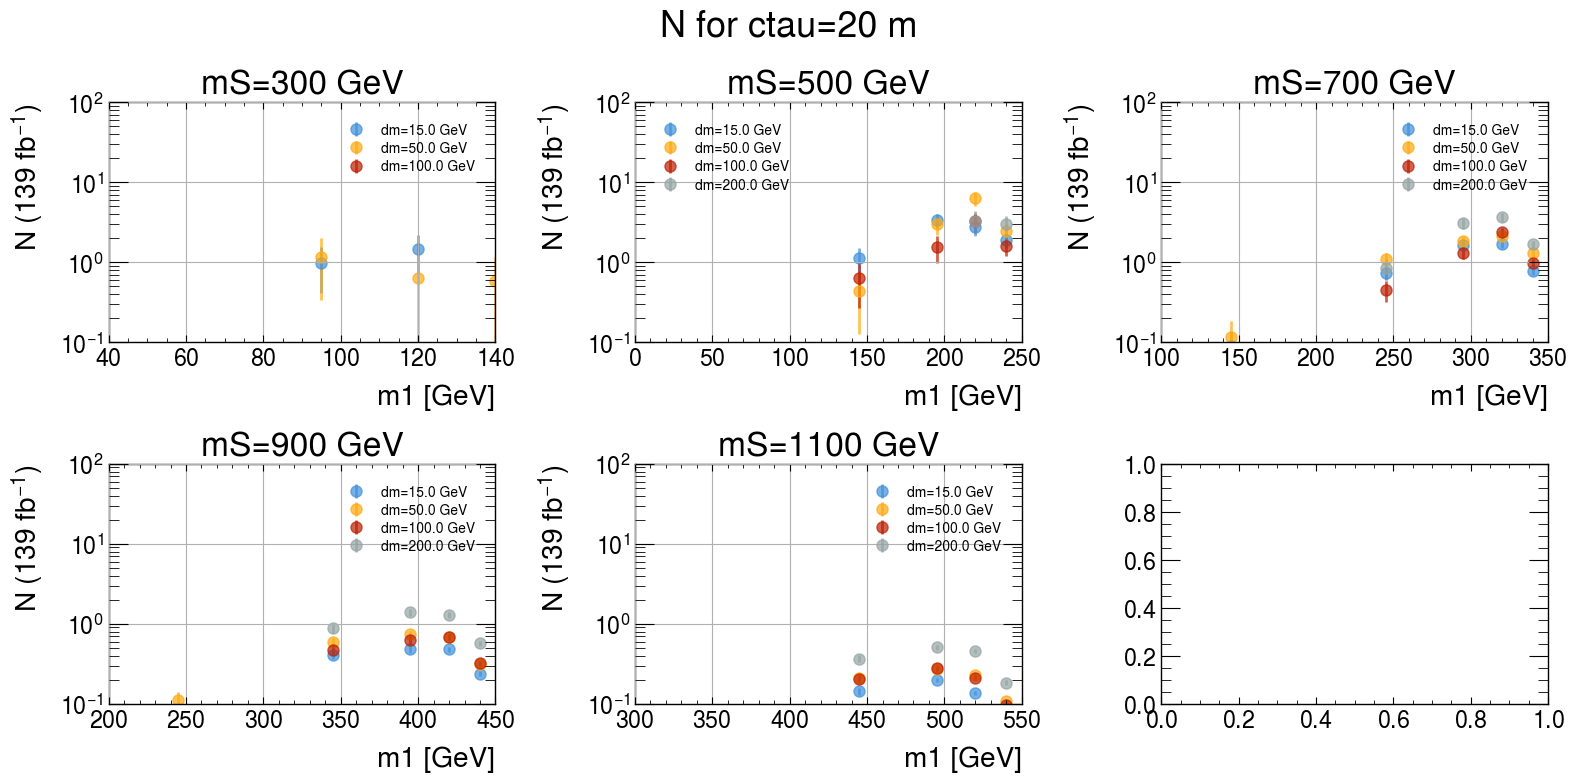

In [6]:
ncolumns = 3
mSValues = sorted(b2tf_DF['ms'].unique())
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = 20.0
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['ctau'].round(0) == ctau)].sort_values(by=['dm', 'm1'])
    alpha=0.7
    for dm,dfB in df.groupby('dm'):        
        axes[iax].errorbar(dfB['m1'], dfB['N_Run2'], 
                            yerr=dfB['N_Run2_err'], fmt='o', label=f'dm={dm:.1f} GeV', alpha=alpha)
        # alpha -= 0.2
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel(r'N (139 fb$^{-1}$)')
    axes[iax].legend(fontsize=10)
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-1, 1e2)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'N for ctau={ctau:.0f} m', fontsize=26)
plt.tight_layout()
plt.show()